**24BAD130 Vishal S DL Lab Exp-08 - TRAIN A SIMPLE AUTOENCODER FOR DIMENSIONALITY REDUCTION AND FEATURE LEARNING**

**PART A: DATASET PREPARATION AND PREPROCESSING**

In [2]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras import layers, Model

np.random.seed(42)
tf.random.set_seed(42)

print("24BAD130 Vishal S")
print("TensorFlow Version:", tf.__version__)

24BAD130 Vishal S
TensorFlow Version: 2.21.0


In [3]:
# Load CIFAR-10 dataset
(x_train, y_train), (x_test, y_test) = tf.keras.datasets.cifar10.load_data()

print("Training images:", x_train.shape)
print("Testing images:", x_test.shape)
print("Training labels:", y_train.shape)
print("Testing labels:", y_test.shape)

170498071/170498071 ━━━━━━━━━━━━━━━━━━━━ 1498s 9us/step
Training images: (50000, 32, 32, 3)
Testing images: (10000, 32, 32, 3)
Training labels: (50000, 1)
Testing labels: (10000, 1)


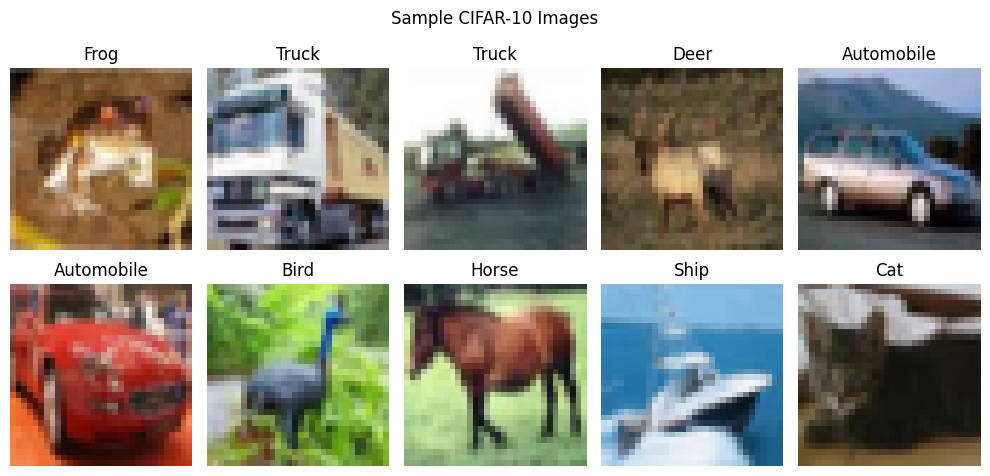

In [5]:
class_names = [
    "Airplane", "Automobile", "Bird", "Cat", "Deer",
    "Dog", "Frog", "Horse", "Ship", "Truck"
]

plt.figure(figsize=(10, 5))

for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(x_train[i])
    plt.title(class_names[int(y_train[i][0])])
    plt.axis("off")

plt.suptitle("Sample CIFAR-10 Images")
plt.tight_layout()
plt.show()

In [6]:
# Convert RGB images to grayscale
x_train_gray = tf.image.rgb_to_grayscale(x_train).numpy()
x_test_gray = tf.image.rgb_to_grayscale(x_test).numpy()

# Normalize pixel values to [0, 1]
x_train_gray = x_train_gray.astype("float32") / 255.0
x_test_gray = x_test_gray.astype("float32") / 255.0

# Flatten each 32 x 32 image into 1024 features
x_train_flat = x_train_gray.reshape(len(x_train_gray), 1024)
x_test_flat = x_test_gray.reshape(len(x_test_gray), 1024)

# Input images are also the target outputs
print("Training data shape:", x_train_flat.shape)
print("Testing data shape:", x_test_flat.shape)
print("Pixel value range:", x_train_flat.min(), "to", x_train_flat.max())
print("Input dimension:", x_train_flat.shape[1])

Training data shape: (50000, 1024)
Testing data shape: (10000, 1024)
Pixel value range: 0.0 to 1.0
Input dimension: 1024


**Part B — Implement the encoder and decoder**

In [7]:
#Build the encoder

input_layer = layers.Input(shape=(1024,), name="encoder_input")

x = layers.Dense(128, activation="relu")(input_layer)
latent = layers.Dense(32, activation="relu", name="latent_layer")(x)

encoder = Model(input_layer, latent, name="Encoder")

encoder.summary()

Model: "Encoder"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ encoder_input (InputLayer)      │ (None, 1024)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       131,200 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ latent_layer (Dense)            │ (None, 32)             │         4,128 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 135,328 (528.62 KB)

 Trainable params: 135,328 (528.62 KB)

 Non-trainable params: 0 (0.00 B)

In [8]:
#Build the decoder

latent_input = layers.Input(shape=(32,), name="decoder_input")

x = layers.Dense(128, activation="relu")(latent_input)
output_layer = layers.Dense(1024, activation="sigmoid")(x)

decoder = Model(latent_input, output_layer, name="Decoder")

decoder.summary()

Model: "Decoder"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ decoder_input (InputLayer)      │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 128)            │         4,224 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1024)           │       132,096 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 136,320 (532.50 KB)

 Trainable params: 136,320 (532.50 KB)

 Non-trainable params: 0 (0.00 B)

In [9]:
#Combine encoder and decoder

autoencoder_input = layers.Input(shape=(1024,), name="autoencoder_input")

encoded = encoder(autoencoder_input)
decoded = decoder(encoded)

autoencoder = Model(
    autoencoder_input,
    decoded,
    name="Autoencoder"
)

autoencoder.summary()

Model: "Autoencoder"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ autoencoder_input (InputLayer)  │ (None, 1024)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Encoder (Functional)            │ (None, 32)             │       135,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Decoder (Functional)            │ (None, 1024)           │       136,320 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 271,648 (1.04 MB)

 Trainable params: 271,648 (1.04 MB)

 Non-trainable params: 0 (0.00 B)

**Part C — Compile and train the autoencoder**

In [10]:
#Compile the model

autoencoder.compile(
    optimizer="adam",
    loss="mse"
)

print("Autoencoder compiled successfully!")

Autoencoder compiled successfully!


In [11]:
#Train the model

history = autoencoder.fit(
    x_train_flat,
    x_train_flat,
    epochs=10,
    batch_size=256,
    shuffle=True,
    validation_data=(x_test_flat, x_test_flat),
    verbose=1
)

Epoch 1/10
196/196 ━━━━━━━━━━━━━━━━━━━━ 6s 25ms/step - loss: 0.0367 - val_loss: 0.0265
Epoch 2/10
196/196 ━━━━━━━━━━━━━━━━━━━━ 3s 16ms/step - loss: 0.0211 - val_loss: 0.0190
Epoch 3/10
196/196 ━━━━━━━━━━━━━━━━━━━━ 3s 16ms/step - loss: 0.0184 - val_loss: 0.0178
Epoch 4/10
196/196 ━━━━━━━━━━━━━━━━━━━━ 3s 17ms/step - loss: 0.0175 - val_loss: 0.0170
Epoch 5/10
196/196 ━━━━━━━━━━━━━━━━━━━━ 5s 16ms/step - loss: 0.0168 - val_loss: 0.0169
Epoch 6/10
196/196 ━━━━━━━━━━━━━━━━━━━━ 3s 15ms/step - loss: 0.0164 - val_loss: 0.0163
Epoch 7/10
196/196 ━━━━━━━━━━━━━━━━━━━━ 3s 15ms/step - loss: 0.0160 - val_loss: 0.0159
Epoch 8/10
196/196 ━━━━━━━━━━━━━━━━━━━━ 5s 23ms/step - loss: 0.0158 - val_loss: 0.0160
Epoch 9/10
196/196 ━━━━━━━━━━━━━━━━━━━━ 3s 15ms/step - loss: 0.0158 - val_loss: 0.0157
Epoch 10/10
196/196 ━━━━━━━━━━━━━━━━━━━━ 3s 15ms/step - loss: 0.0157 - val_loss: 0.0157


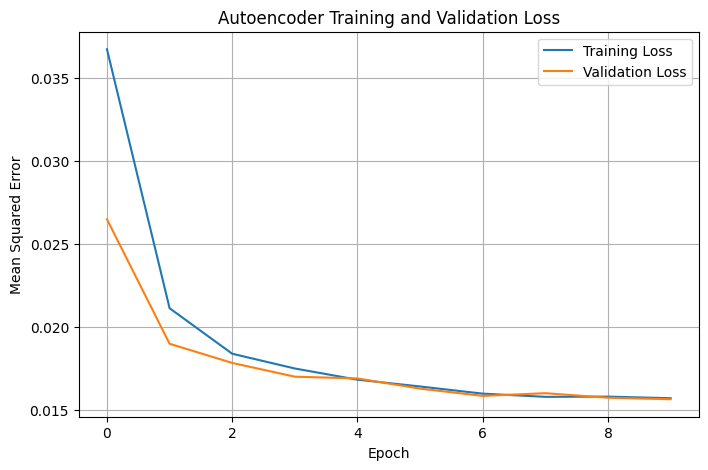

Final Training Loss: 0.01571080833673477
Final Validation Loss: 0.015650680288672447


In [12]:
#Plot training and validation loss

plt.figure(figsize=(8, 5))

plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")

plt.title("Autoencoder Training and Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Mean Squared Error")
plt.legend()
plt.grid(True)
plt.show()

print("Final Training Loss:", history.history["loss"][-1])
print("Final Validation Loss:", history.history["val_loss"][-1])

**Part D — Dimensionality reduction and reconstruction**

In [13]:
#Extract latent features
# Encode test images
latent_features = encoder.predict(x_test_flat, batch_size=256)

print("Original input dimension:", x_test_flat.shape[1])
print("Latent representation shape:", latent_features.shape)
print("Reduced dimension:", latent_features.shape[1])
print("Feature reduction:",
      round((1 - 32 / 1024) * 100, 2), "%")

40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step
Original input dimension: 1024
Latent representation shape: (10000, 32)
Reduced dimension: 32
Feature reduction: 96.88 %


In [14]:
# Reconstruct test images
reconstructed = autoencoder.predict(x_test_flat, batch_size=256)

print("Original data shape:", x_test_flat.shape)
print("Reconstructed data shape:", reconstructed.shape)

test_loss = autoencoder.evaluate(
    x_test_flat,
    x_test_flat,
    verbose=0
)

print("Test Reconstruction Loss (MSE):", test_loss)

40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step
Original data shape: (10000, 1024)
Reconstructed data shape: (10000, 1024)
Test Reconstruction Loss (MSE): 0.01565067656338215


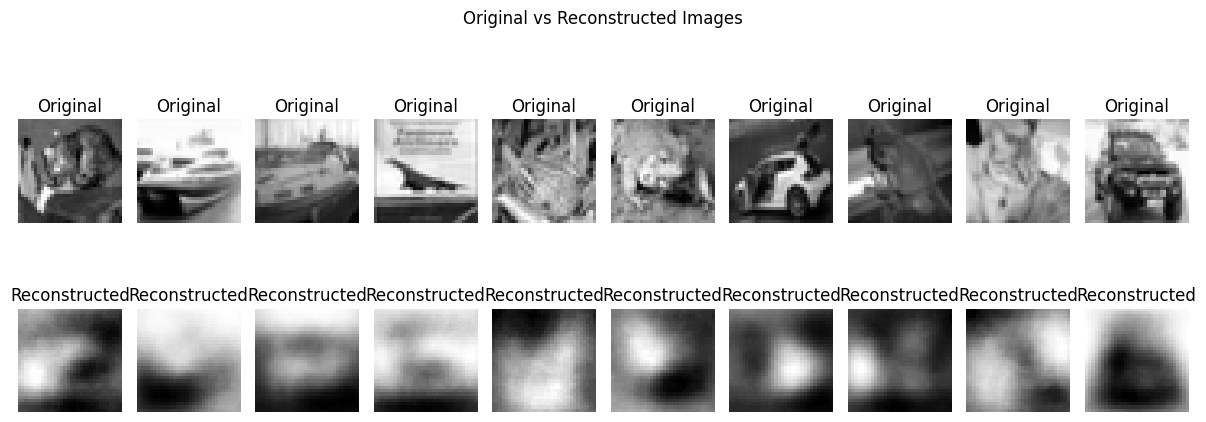

In [15]:
#Display original and reconstructed images side by side

plt.figure(figsize=(12, 5))

for i in range(10):
    # Original image
    plt.subplot(2, 10, i + 1)
    plt.imshow(x_test_flat[i].reshape(32, 32), cmap="gray")
    plt.title("Original")
    plt.axis("off")

    # Reconstructed image
    plt.subplot(2, 10, i + 11)
    plt.imshow(reconstructed[i].reshape(32, 32), cmap="gray")
    plt.title("Reconstructed")
    plt.axis("off")

plt.suptitle("Original vs Reconstructed Images")
plt.tight_layout()
plt.show()

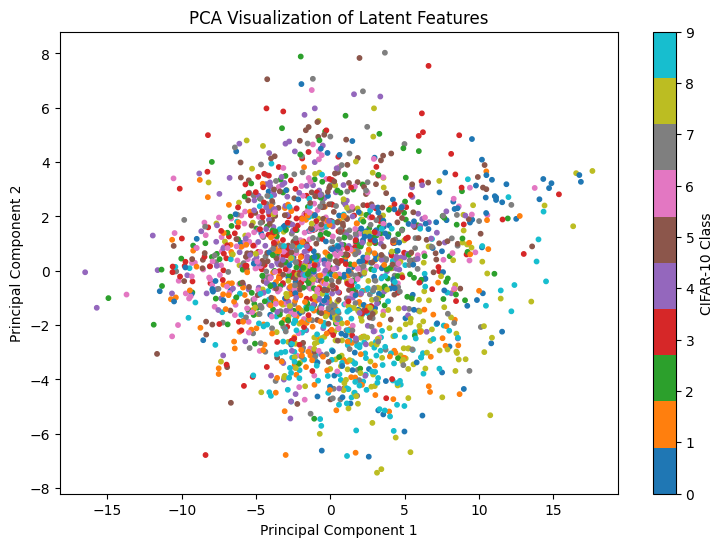

Variance retained by 2D PCA: 68.37 %


In [16]:
#Visualize the latent representation using PCA (optional)

from sklearn.decomposition import PCA

# Use 2000 samples to keep visualization simple
features = latent_features[:2000]
labels = y_test[:2000].flatten()

# Reduce latent features to 2 dimensions
pca = PCA(n_components=2)
features_2d = pca.fit_transform(features)

plt.figure(figsize=(9, 6))

scatter = plt.scatter(
    features_2d[:, 0],
    features_2d[:, 1],
    c=labels,
    cmap="tab10",
    s=10
)

plt.title("PCA Visualization of Latent Features")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.colorbar(scatter, label="CIFAR-10 Class")
plt.show()

print("Variance retained by 2D PCA:",
      round(sum(pca.explained_variance_ratio_) * 100, 2), "%")

In [17]:
#Save the trained model and reconstructed images

# Save the complete autoencoder
autoencoder.save("cifar10_autoencoder.keras")

# Save encoder separately
encoder.save("cifar10_encoder.keras")

# Save reconstructed images
np.save("reconstructed_images.npy", reconstructed)

print("Autoencoder model saved successfully!")
print("Encoder model saved successfully!")
print("Reconstructed images saved successfully!")

Autoencoder model saved successfully!
Encoder model saved successfully!
Reconstructed images saved successfully!
